In [1]:
from dotenv import load_dotenv
load_dotenv()

from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-5.4-mini", stream_usage=True,temperature=0.7)


In [2]:
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage


llm = ChatOpenAI(
    model="gpt-5-nano",
   
)

llm.invoke([HumanMessage(content="who is messi!")])

AIMessage(content='Lionel Messi is an Argentine professional footballer who’s widely regarded as one of the greatest players of all time.\n\n- Full name: Lionel Andrés Messi Cuccittini\n- Born: June 24, 1987, in Rosario, Argentina\n- Position: Forward/attacking midfielder\n- Clubs (notable): FC Barcelona (2000s–2021), Paris Saint-Germain (2021–2023), Inter Miami (from 2023)\n- National team: Argentina (captain), all-time top scorer for the country\n- Major achievements: 2022 FIFA World Cup winner with Argentina; Copa América winner (2021); multiple Ballon d’Or winner (several times)\n- Nickname: La Pulga (The Flea)\n\nIf you’d like, I can give you a quick timeline of his career, or highlight reels and key records.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 1787, 'prompt_tokens': 11, 'total_tokens': 1798, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 1600, 'rejected_prediction_tok

In [3]:
from typing import TypedDict, List, Annotated
from operator import add

class graph_schema(TypedDict):
    messages_manual:List
    messages_auto : Annotated[List,add]

In [4]:
def create_post(state:graph_schema) -> graph_schema:
    messages_manual=state['messages_manual']
    
    response_manual=llm.invoke(messages_manual).content
    
    response_manual_ai=AIMessage(content=response_manual)
    state['messages_manual']=messages_manual + [response_manual_ai]
    
    messages_auto=state['messages_auto']
    response_auto=llm.invoke(messages_auto).content
    response_auto_ai=AIMessage(content=response_auto)
    state['messages_auto']=[response_auto_ai]

    return state

def curated_post(state:graph_schema)->graph_schema:
    messages_manual=state['messages_manual']
    
    response_manual=llm.invoke(messages_manual).content
    
    response_manual_ai=AIMessage(content=response_manual)
    state['messages_manual']=messages_manual + [response_manual_ai]
    
    messages_auto=state['messages_auto']
    response_auto=llm.invoke(messages_auto).content
    response_auto_ai=AIMessage(content=response_auto)
    state['messages_auto']=[response_auto_ai]

    return state
    

In [5]:
from langgraph.graph import StateGraph, END, START


graph=StateGraph(graph_schema)

graph.add_node("create_post",create_post)
graph.add_node("curated_post",curated_post)

graph.add_edge(START,"create_post")
graph.add_edge("create_post", "curated_post")
graph.add_edge("curated_post", END)

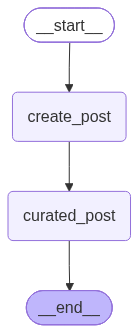

In [6]:
from IPython.display import Image, display

messages_graph=graph.compile()

Image(messages_graph.get_graph().draw_mermaid_png())

In [8]:
messages_graph.invoke(
    {"messages_manual":[HumanMessage(content="The importance of data privacy in digital age")],
     "messages_auto":[HumanMessage(content="The importance of data privacy in digital age")]}
    )


{'messages_manual': [HumanMessage(content='The importance of data privacy in digital age', additional_kwargs={}, response_metadata={}),
  AIMessage(content='Data privacy in the digital age: why it matters and what to do about it\n\nWhat is data privacy?\n- Data privacy is about having control over your personal information: what is collected about you, how it is used, who it is shared with, how long it is stored, and under what circumstances. It also covers your rights to access, correct, delete, or withdraw consent for your data.\n\nWhy data privacy matters in today’s world\n- Autonomy and dignity: Personal data can reveal sensitive details about beliefs, health, finances, location, and behavior. Uncontrolled access can shape decisions about you without your awareness or input.\n- Security and financial protection: Data breaches can lead to identity theft, fraud, and financial loss. Even seemingly innocuous data can be misused in combination with other data.\n- Trust and freedom of ex